# Cross-lingual lie detection

What is it about??

## Load Dependencies

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

from convokit import Corpus, download

## Load data

In [23]:
# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

def load_dataset(corpus_name="diplomacy-corpus"):
    """Download and load the Cornell Diplomacy corpus."""
    corpus = Corpus(filename=download(corpus_name))

    rows = []
    for utt in corpus.iter_utterances():
        rows.append({
            "message_id": utt.id,
            "conversation_id": utt.conversation_id,
            "speaker": utt.speaker.id if utt.speaker else None,
            "text": utt.text,
            "reply_to": utt.reply_to,
            **utt.meta
        })

    df = pd.DataFrame(rows)
    df["text"] = df["text"].fillna("").astype(str)
    return df


In [24]:
df = load_dataset()
df

Dataset already exists at /home/ucloud/.convokit/saved-corpora/diplomacy-corpus


,message_id,conversation_id,speaker,text,reply_to,speaker_intention,receiver_perception,receiver,absolute_message_index,relative_message_index,year,game_score,game_score_delta,deception_quadrant
0,Game1-italy-germany-0,Game1-italy-germany,italy-Game1,Germany!\n\nJust the person I want to speak wi...,NaN,Truth,Truth,germany-Game1,74,0,1901,3,0,Straightforward
1,Game1-italy-germany-1,Game1-italy-germany,germany-Game1,"You've whet my appetite, Italy. What's the sug...",Game1-italy-germany-0,Truth,Truth,italy-Game1,76,1,1901,3,0,Straightforward
2,Game1-italy-germany-2,Game1-italy-germany,italy-Game1,👍,Game1-italy-germany-1,Truth,Truth,germany-Game1,86,2,1901,3,0,Straightforward
3,Game1-italy-germany-3,Game1-italy-germany,germany-Game1,It seems like there are a lot of ways that cou...,Game1-italy-germany-2,Truth,Truth,italy-Game1,87,3,1901,3,0,Straightforward
4,Game1-italy-germany-4,Game1-italy-germany,italy-Game1,"Yeah, I can’t say I’ve tried it and it works, ...",Game1-italy-germany-3,Truth,NaN,germany-Game1,89,4,1901,3,0,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17284,Game9-turkey-france-29,Game9-turkey-france,turkey-Game9,Mm I see,Game9-turkey-france-28,Truth,Truth,france-Game9,1367,29,1903,4,-1,Straightforward
17285,Game9-turkey-france-30,Game9-turkey-france,turkey-Game9,"Well, just putting the option out there I guess",Game9-turkey-france-29,Truth,Truth,france-Game9,1368,30,1903,4,-1,Straightforward
17286,Game9-turkey-france-31,Game9-turkey-france,turkey-Game9,you have anything else in mind?,Game9-turkey-france-30,Truth,Truth,france-Game9,1369,31,1903,4,-1,Straightforward
17287,Game9-turkey-france-32,Game9-turkey-france,turkey-Game9,I guess I'd also be happy to support you into ...,Game9-turkey-france-31,Truth,Truth,france-Game9,1370,32,1903,4,-1,Straightforward


## Descriptive stats

In [ ]:
# --------------------------------------------------
# 2. make a table with descriptive statistics
# --------------------------------------------------

def descriptive_summary(df):
    """
    Function for making a descriptive table containing: 
    
    """
    # number of games
    n_games = df["conversation_id"].nunique()
    n_speakers = df["speaker"].nunique()
    n_messages = len(df)


    # sentence lengths in words
    sentence_lengths = []
    for message in df["text"].fillna(""):
        sentences = re.split(r"[.!?]+", message)
        for sentence in sentences:
            words = sentence.split()
            if words:
                sentence_lengths.append(len(words))

    # truth vs. lies
    intention_counts = df["speaker_intention"].value_counts(dropna=False)

    summary = [
        {"Statistic": "Number of games", "Value": int(n_games)},
        {"Statistic": "Number of speakers", "Value": int(n_speakers)},
        {"Statistic": "Number of messages", "Value": int(n_messages)},

        {
            "Statistic": "Mean sentence length (words)",
            "Value": round(pd.Series(sentence_lengths).mean())
        },
        {
            "Statistic": "SD sentence length (words)",
            "Value": round(pd.Series(sentence_lengths).std())
        }
    ]

    # truth vs. lies counts 
    for label, count in intention_counts.items():
        summary.append({
            "Statistic": f"Speaker intention: {label}",
            "Value": int(count)
        })


    return pd.DataFrame(summary)


summary_table = descriptive_summary(df)
display(summary_table)

,Statistic,Value
0,Number of games,246
1,Number of speakers,83
2,Number of messages,17289
3,Mean sentence length (words),11
4,SD sentence length (words),9
5,Speaker intention: Truth,16402
6,Speaker intention: Lie,887


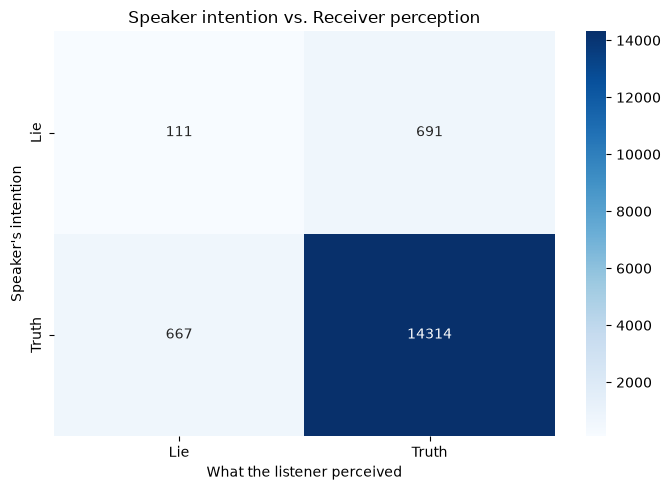

In [ ]:
# --------------------------------------------------
# 3. plot the deception quadrant
# --------------------------------------------------

def plot_deception_matrix(df):
    """
    Plot matrix of perceived vs actual truths/lies
    """
    matrix = pd.crosstab(
        df["speaker_intention"],
        df["receiver_perception"]
    )

    # plot the matrix as a heatmap, displaying message counts in each cell
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("Speaker intention vs. Receiver perception")
    plt.xlabel("What the listener perceived")
    plt.ylabel("Speaker's intention")
    plt.tight_layout()

    plt.savefig("../plots/deception_matrix.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


plot_deception_matrix(df)